# What drives the smog (SHAP)

SHAP splits every prediction into contributions of each feature.
Uses the LightGBM model saved by `train.py`.

In [1]:
import sys
sys.path.append("../src")

import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
import shap

from config import EMBASSY_END, FIGURES_DIR, MODELS_DIR
from features import feature_columns, make_features

In [2]:
daily = make_features().dropna(subset=["target"])
cols = feature_columns(daily)
model = lgb.Booster(model_file=str(MODELS_DIR / "lgbm.txt"))

# explain the heating season days, summer is boring
data = daily[(daily.heating == 1) & (daily.date < EMBASSY_END)]
X = data[cols]
X.shape

(758, 38)

In [3]:
explainer = shap.TreeExplainer(model)
sv = explainer(X)

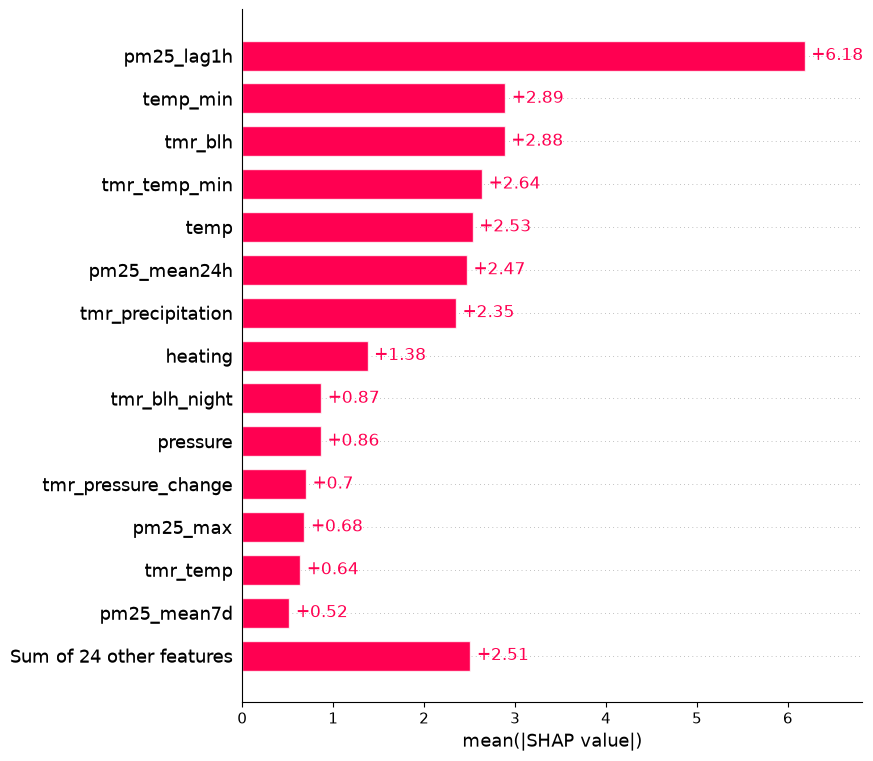

In [4]:
shap.plots.bar(sv, max_display=15, show=False)
plt.savefig(FIGURES_DIR / "shap_importance.png", dpi=120, bbox_inches="tight")

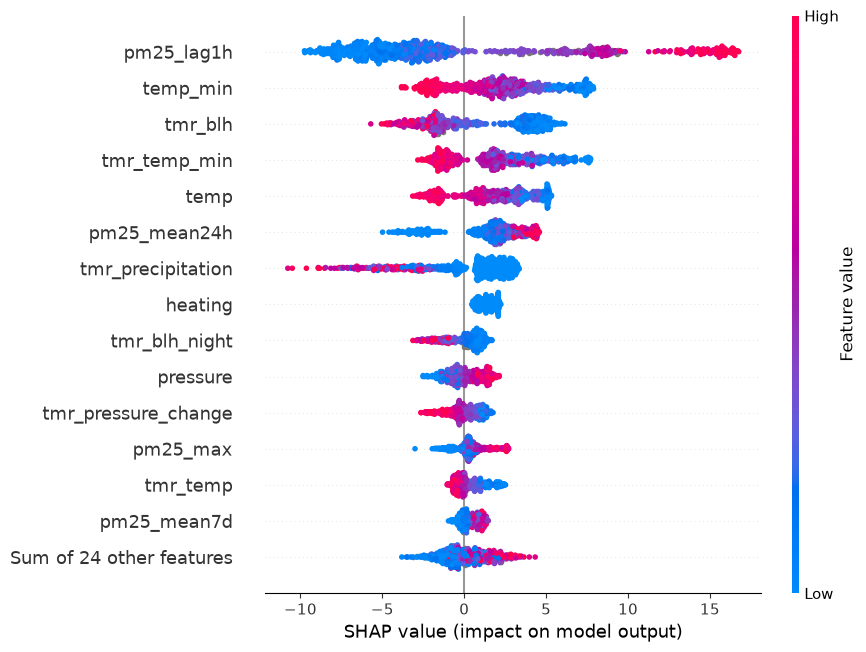

In [5]:
shap.plots.beeswarm(sv, max_display=15)

## Weather, heating or traffic?

Group features and add up how much each group moves the forecast (mean |SHAP|).
"Traffic" is only a proxy here: weekday/weekend and holidays. I don't have real traffic data.

In [6]:
groups = {
    "past smog": [c for c in cols if c.startswith("pm25")],
    "weather": [c for c in cols if any(w in c for w in ["temp", "humid", "wind", "pressure", "precip", "blh"])],
    "heating / season": ["heating", "month", "dayofyear"],
    "calendar (weekday, holidays)": ["dayofweek", "weekend", "holiday", "tmr_dayofweek", "tmr_weekend", "tmr_holiday"],
}
# check that every feature is in exactly one group
grouped = sum(groups.values(), [])
print("not in a group:", set(cols) - set(grouped))

contrib = pd.DataFrame(abs(sv.values), columns=cols)
by_group = pd.Series({g: contrib[c].sum(axis=1).mean() for g, c in groups.items()})
by_group = by_group.sort_values()
by_group.round(2)

not in a group: set()


calendar (weekday, holidays)     0.03
heating / season                 1.46
past smog                       10.50
weather                         18.11
dtype: float64

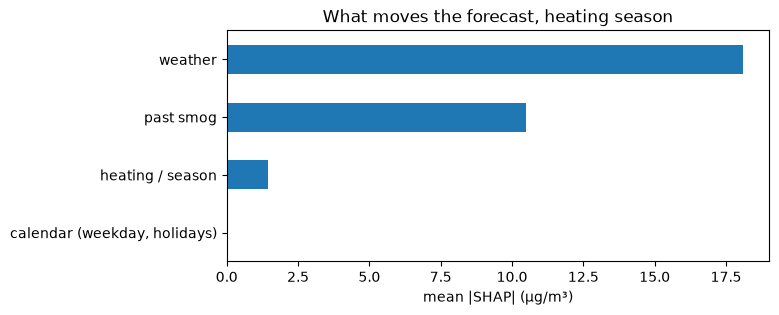

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
by_group.plot.barh(ax=ax)
ax.set_xlabel("mean |SHAP| (µg/m³)")
ax.set_title("What moves the forecast, heating season")
fig.savefig(FIGURES_DIR / "shap_groups.png", dpi=120, bbox_inches="tight")

In [8]:
# same without the "past smog" group. past smog is itself caused by weather and heating,
# so this is a fairer look at the other three
by_group.drop("past smog") / by_group.drop("past smog").sum()

calendar (weekday, holidays)    0.001660
heating / season                0.074587
weather                         0.923753
dtype: float64

## A few very dirty days

In [9]:
dirty = data.sort_values("target", ascending=False).head(3)
dirty[["date", "target", "pm25_mean24h", "tmr_temp", "tmr_wind", "tmr_blh"]].set_index("date").round(1)

,target,pm25_mean24h,tmr_temp,tmr_wind,tmr_blh
date,,,,,
2020-12-23,222.0,NaN,-9.8,8.5,34.2
2020-12-24,204.1,222.0,-5.6,7.6,29.0
2023-01-15,204.1,NaN,-13.8,9.3,24.0


2020-12-23 -> next day real: 222.0


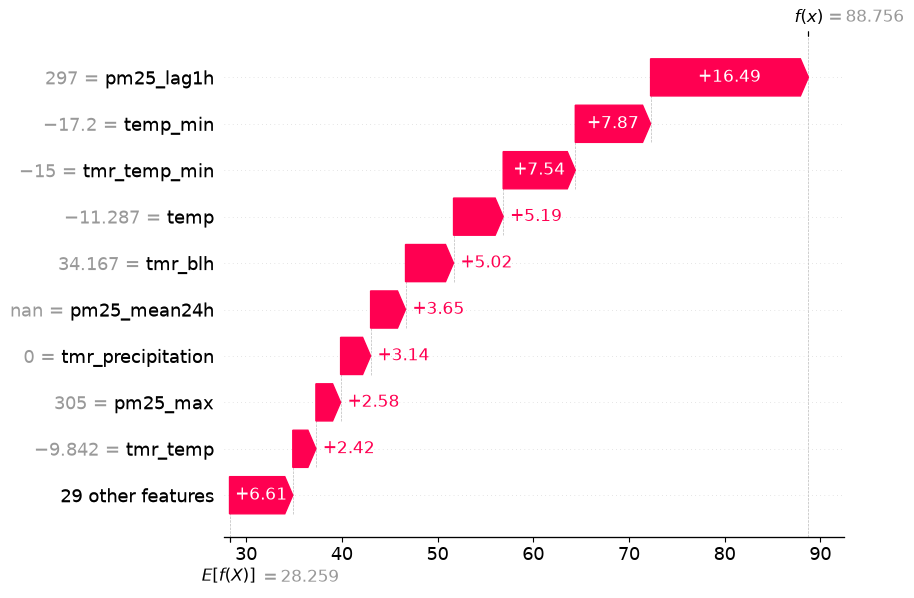

2020-12-24 -> next day real: 204.1


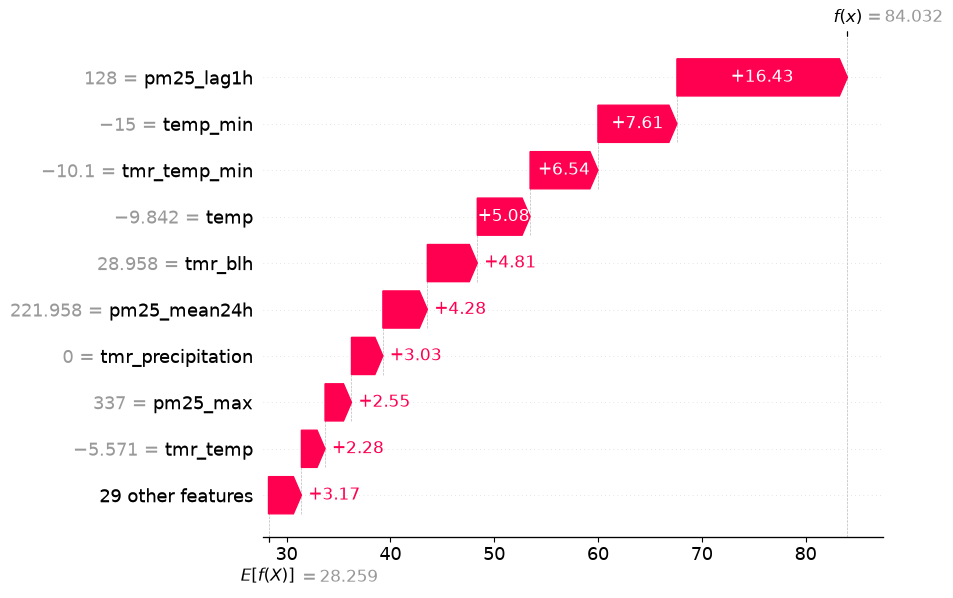

2023-01-15 -> next day real: 204.1


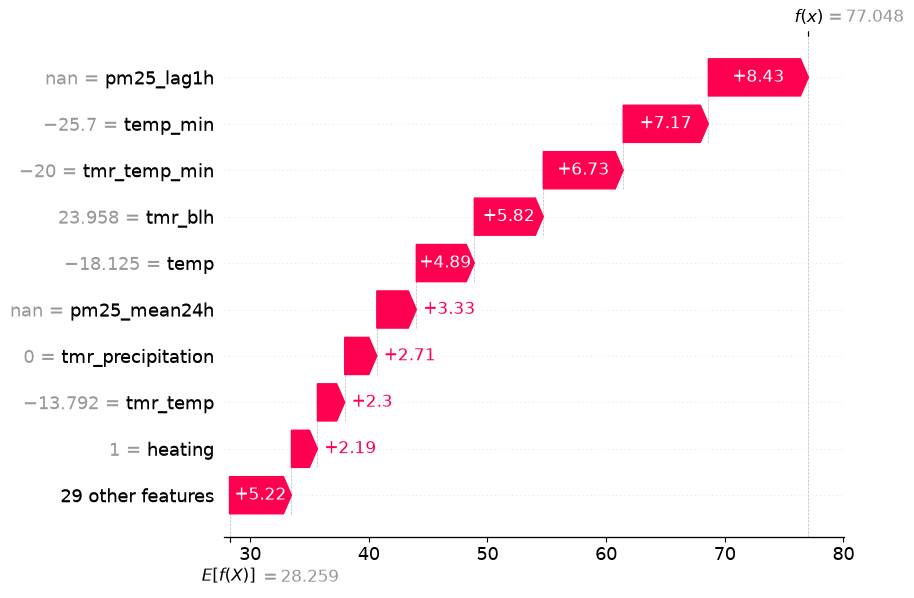

In [10]:
for i in dirty.index:
    pos = data.index.get_loc(i)
    print(data.loc[i, "date"].date(), "-> next day real:", round(data.loc[i, "target"], 1))
    shap.plots.waterfall(sv[pos], max_display=10)

### Conclusion

- Weather seems to have the biggest impact on air pollution. Without including previous pollution levels, weather accounts for around 92%, while heating and season account for about 7%. Traffic has almost no effect in my model.

- The most polluted days are usually cold days when the boundary layer height (BLH) is very low. This means pollution stays closer to the ground instead of spreading out.

- One thing I noticed is that weather and heating are connected. People burn more coal when it's cold, so some of what the model shows as a weather effect might actually be related to heating.

- I also can't really make a strong conclusion about traffic because I didn't have actual traffic data. So even though the model shows almost 0%, it doesn't mean cars don't contribute to air pollution.